In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import (
    compute_actual_affected_points,
    run_counterfactual_scenario,
)

df_adj = pd.read_parquet("../data/processed/atp_long_with_elo_2021_2026.parquet")
big3 = ["Alexander Zverev", "Jannik Sinner", "Carlos Alcaraz"]

# 1. Race oficial ATP 2026 justo antes de Turín (9 nov 2026)
OFFICIAL_PRE_TURIN_RACE = {
    "Alexander Zverev": 9350,
    "Jannik Sinner": 7950,
    "Carlos Alcaraz": 6100,
}

# Descontar los 9 Big Titles afectados para aislar los puntos base exactos
actual_affected = compute_actual_affected_points(df_adj, big3)
display(actual_affected)

baseline_pts = {
    p: int(OFFICIAL_PRE_TURIN_RACE[p] - actual_affected[p].sum())
    for p in big3
}
print("Puntos base fijos (Ene-Abr + ATP 500/250):", baseline_pts)

# 2. Ejecutar 4 configuraciones (10.000 temporadas cada una)
scenarios = {
    "Sanity Check (Lesiones reales)": dict(alcaraz_healthy=False, sinner_healthy=False),
    "Solo Alcaraz sano":              dict(alcaraz_healthy=True,  sinner_healthy=False),
    "Solo Sinner sano":               dict(alcaraz_healthy=False, sinner_healthy=True),
    "Ambos sanos (100% disponibles)": dict(alcaraz_healthy=True,  sinner_healthy=True),
}

results = {}
summary_rows = []

for label, params in scenarios.items():
    sim_df = run_counterfactual_scenario(
        df_adj=df_adj,
        baseline_pts=baseline_pts,
        n_sims=10_000,
        form_sigma=25.0,
        seed=42,
        **params,
    )
    results[label] = sim_df
    probs = sim_df["year_end_no1"].value_counts(normalize=True) * 100.0
    summary_rows.append({
        "Escenario": label,
        "P(Zverev #1) %": round(probs.get("Alexander Zverev", 0.0), 1),
        "P(Sinner #1) %": round(probs.get("Jannik Sinner", 0.0), 1),
        "P(Alcaraz #1) %": round(probs.get("Carlos Alcaraz", 0.0), 1),
        "Media Pts Zverev": int(sim_df["Alexander Zverev"].mean()),
        "Media Pts Sinner": int(sim_df["Jannik Sinner"].mean()),
        "Media Pts Alcaraz": int(sim_df["Carlos Alcaraz"].mean()),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,tournament,Alexander Zverev,Jannik Sinner,Carlos Alcaraz
0,madrid,650,1000,0
1,rome,100,1000,0
2,roland_garros,2000,50,0
3,wimbledon,1300,2000,0
4,canada,10,0,0
5,cincinnati,100,0,0
6,us_open,2000,0,400
7,shanghai,400,0,50
8,paris,50,0,1000


Puntos base fijos (Ene-Abr + ATP 500/250): {'Alexander Zverev': 2740, 'Jannik Sinner': 3900, 'Carlos Alcaraz': 4650}


,Escenario,P(Zverev #1) %,P(Sinner #1) %,P(Alcaraz #1) %,Media Pts Zverev,Media Pts Sinner,Media Pts Alcaraz
0,Sanity Check (Lesiones reales),8.9,44.3,46.8,6459,7996,8106
1,Solo Alcaraz sano,0.1,0.5,99.4,6074,7597,12922
2,Solo Sinner sano,0.1,99.6,0.3,6090,13259,7594
3,Ambos sanos (100% disponibles),0.0,58.6,41.4,5751,12770,12280


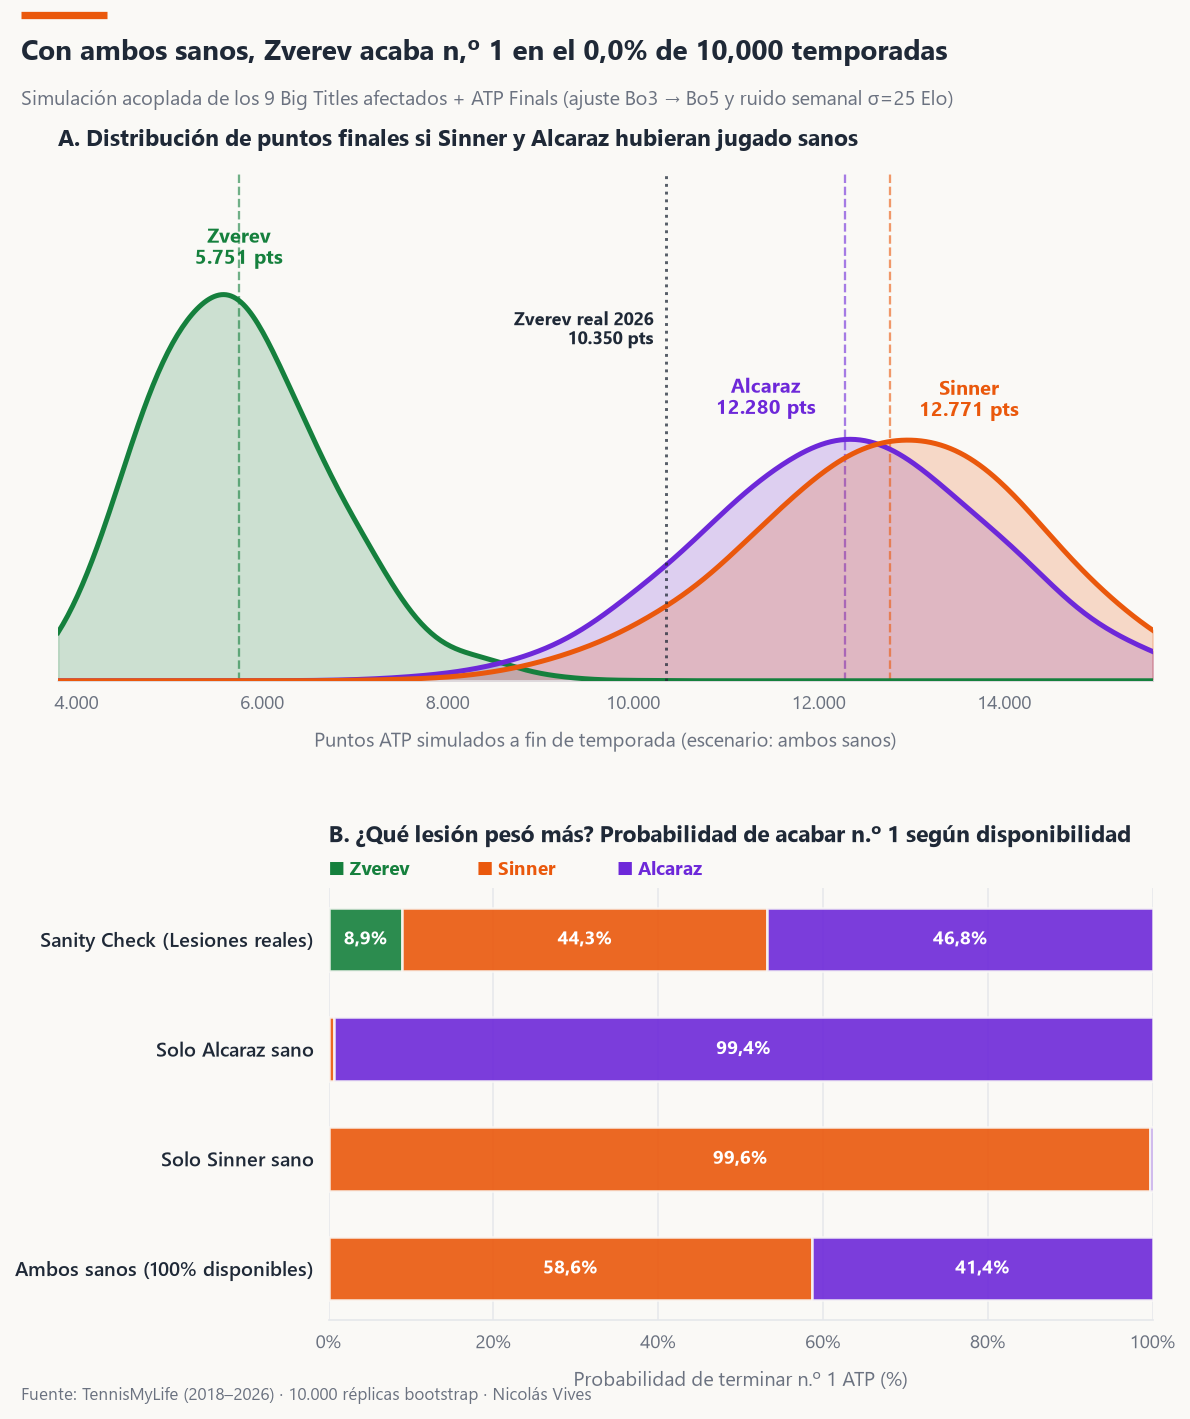

In [10]:
from scipy.stats import gaussian_kde
from src.viz import PALETTE, apply_editorial_style, add_editorial_chrome, save_figure

apply_editorial_style()

colors = {
    "Alexander Zverev": PALETTE["zverev"],
    "Jannik Sinner": PALETTE["sinner"],
    "Carlos Alcaraz": PALETTE["alcaraz"],
}

sim_both = results["Ambos sanos (100% disponibles)"]
p_zverev_both = (sim_both["year_end_no1"] == "Alexander Zverev").mean() * 100.0

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8.2, 9.6), gridspec_kw={"height_ratios": [1.18, 1.0]}
)

# --- PANEL SUPERIOR: Curvas de densidad (KDE) en escenario "Ambos sanos" ---
ax1.spines["left"].set_visible(False)
ax1.grid(axis="x", visible=False)
ax1.set_yticks([])

x_grid = np.linspace(3800, 15600, 450)
label_shifts = {
    "Alexander Zverev": (0, 1.08),
    "Carlos Alcaraz": (-850, 1.08),
    "Jannik Sinner": (850, 1.08),
}

max_dens = 0.0
for p in ["Alexander Zverev", "Carlos Alcaraz", "Jannik Sinner"]:
    vals = sim_both[p].to_numpy()
    kde = gaussian_kde(vals, bw_method=0.28)
    y_dens = kde(x_grid)
    max_dens = max(max_dens, y_dens.max())

    ax1.fill_between(x_grid, y_dens, color=colors[p], alpha=0.20, zorder=2)
    ax1.plot(x_grid, y_dens, color=colors[p], lw=2.4, zorder=3)

    mean_v = vals.mean()
    peak_y = float(kde(mean_v)[0])
    dx, y_mult = label_shifts[p]
    ax1.axvline(mean_v, color=colors[p], linestyle="--", lw=1.1, alpha=0.6, zorder=2)
    ax1.text(
        mean_v + dx, peak_y * y_mult,
        f"{p.split()[-1]}\n{mean_v:,.0f} pts".replace(",", "."),
        color=colors[p], fontsize=9.5, fontweight="bold", ha="center", va="bottom",
    )

# Línea de referencia con los puntos reales finales de Zverev tras Turín
ax1.axvline(10350, color=PALETTE["text"], linestyle=":", lw=1.4, alpha=0.75, zorder=4)
ax1.text(
    10220, max_dens * 0.96,
    "Zverev real 2026\n10.350 pts",
    color=PALETTE["text"], fontsize=8.5, fontweight="bold", ha="right", va="top",
)

ax1.set_ylim(0, max_dens * 1.32)
ax1.set_xlim(3800, 15600)
ax1.xaxis.set_major_formatter(lambda x, _: f"{int(x):,}".replace(",", "."))
ax1.set_xlabel("Puntos ATP simulados a fin de temporada (escenario: ambos sanos)")
ax1.set_title(
    "A. Distribución de puntos finales si Sinner y Alcaraz hubieran jugado sanos",
    fontsize=10.8, fontweight="bold", color=PALETTE["text"], loc="left", pad=12,
)

# --- PANEL INFERIOR: Probabilidad de terminar n.º 1 por escenario ---
ax2.spines["left"].set_visible(False)
ax2.grid(axis="y", visible=False)

plot_scen = summary_df.iloc[::-1].reset_index(drop=True)
y_pos = np.arange(len(plot_scen))
left = np.zeros(len(plot_scen))

series_spec = [
    ("P(Zverev #1) %", "Alexander Zverev"),
    ("P(Sinner #1) %", "Jannik Sinner"),
    ("P(Alcaraz #1) %", "Carlos Alcaraz"),
]

for col, name in series_spec:
    vals = plot_scen[col].to_numpy()
    ax2.barh(y_pos, vals, left=left, height=0.58, color=colors[name], alpha=0.90, edgecolor=PALETTE["bg"], lw=1.2)
    for i, v in enumerate(vals):
        if v >= 8.0:
            ax2.text(
                left[i] + v / 2, i, f"{v:.1f}%".replace(".", ","),
                va="center", ha="center", color="white", fontweight="bold", fontsize=9.2,
            )
    left += vals

# Clave de color en línea arriba del panel B (sin caja de leyenda)
ax2.text(0.00, 1.03, "■ Zverev", transform=ax2.transAxes, color=PALETTE["zverev"], fontsize=9.2, fontweight="bold")
ax2.text(0.18, 1.03, "■ Sinner", transform=ax2.transAxes, color=PALETTE["sinner"], fontsize=9.2, fontweight="bold")
ax2.text(0.35, 1.03, "■ Alcaraz", transform=ax2.transAxes, color=PALETTE["alcaraz"], fontsize=9.2, fontweight="bold")

ax2.set_yticks(y_pos)
ax2.set_yticklabels(plot_scen["Escenario"], color=PALETTE["text"], fontweight="medium", fontsize=9.5)
ax2.set_xlim(0, 100)
ax2.xaxis.set_major_formatter(lambda x, _: f"{int(x)}%")
ax2.set_xlabel("Probabilidad de terminar n.º 1 ATP (%)")
ax2.set_title(
    "B. ¿Qué lesión pesó más? Probabilidad de acabar n.º 1 según disponibilidad",
    fontsize=10.8, fontweight="bold", color=PALETTE["text"], loc="left", pad=22,
)

add_editorial_chrome(
    fig,
    title=f"Con ambos sanos, Zverev acaba n.º 1 en el {p_zverev_both:.1f}% de 10.000 temporadas".replace(".", ","),
    subtitle="Simulación acoplada de los 9 Big Titles afectados + ATP Finals (ajuste Bo3 → Bo5 y ruido semanal σ=25 Elo)",
    source="Fuente: TennisMyLife (2018–2026) · 10.000 réplicas bootstrap · Nicolás Vives",
    accent_color=PALETTE["sinner"],
    left=0.29,
    right=0.96,
    top_pad_in=1.22,
    bottom_pad_in=0.72,
    hspace=0.44,
)

# El panel superior no necesita tanto margen izquierdo como las etiquetas largas del panel inferior
pos1 = ax1.get_position()
ax1.set_position([0.07, pos1.y0, 0.89, pos1.height])

save_figure(fig, "03_montecarlo_counterfactual_2026")
plt.show()